# Control óptimo de EDOs — Clase 5
**Controles acotados**

FCEN–UBA. Bibliografía principal: Lenhart & Workman, *Optimal Control Applied to Biological Models* (2007).

> Convención del curso: problemas de **máximo** y Hamiltoniano $H = L + \lambda f$.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, solve_bvp
from scipy.optimize import brentq, minimize
plt.rcParams.update({'figure.figsize': (7, 3.5), 'axes.grid': True, 'grid.alpha': 0.3})

In [2]:
def rk4(F, y0, t):
    """Integra y' = F(t, y) en la grilla t con Runge-Kutta 4."""
    y = np.zeros((len(t), np.size(y0))); y[0] = y0
    for k in range(len(t) - 1):
        h = t[k+1] - t[k]
        k1 = F(t[k], y[k]); k2 = F(t[k] + h/2, y[k] + h/2*k1)
        k3 = F(t[k] + h/2, y[k] + h/2*k2); k4 = F(t[k] + h, y[k] + h*k3)
        y[k+1] = y[k] + h/6*(k1 + 2*k2 + 2*k3 + k4)
    return y

def fbsm(f, dlam, ucalc, x0, lamT, T, N=1000, m=1, u0=None,
         omega=0.5, tol=1e-3, maxit=2000, historia=False):
    """Forward-Backward Sweep (Lenhart & Workman, cap. 4). Problema de MÁXIMO.
    f(t,x,u)        -> x'                  (arreglos de dimensión n)
    dlam(t,x,u,lam) -> lam' = -H_x
    ucalc(t,x,lam)  -> control dado por el PMP (dimensión m)
    lamT(xT)        -> lam(T) (condición de transversalidad)
    Devuelve un diccionario con t, x, u, lam, iteraciones (y la historia de u)."""
    t = np.linspace(0, T, N+1); h = T/N
    x0 = np.atleast_1d(np.asarray(x0, float)); n = len(x0)
    u = np.zeros((N+1, m)) if u0 is None else np.array(u0, float).reshape(N+1, m)
    x = np.zeros((N+1, n)); lam = np.zeros((N+1, n)); hist = []
    rel = lambda a, b: np.sum(np.abs(a - b)) / max(np.sum(np.abs(a)), 1e-12)
    for it in range(maxit):
        uo, xo, lo = u.copy(), x.copy(), lam.copy()
        x[0] = x0                                   # Paso 1: estado hacia adelante
        for k in range(N):
            um = 0.5*(u[k] + u[k+1])
            k1 = f(t[k], x[k], u[k]); k2 = f(t[k]+h/2, x[k]+h/2*k1, um)
            k3 = f(t[k]+h/2, x[k]+h/2*k2, um); k4 = f(t[k]+h, x[k]+h*k3, u[k+1])
            x[k+1] = x[k] + h/6*(k1 + 2*k2 + 2*k3 + k4)
        lam[N] = lamT(x[N])                         # Paso 2: adjunto hacia atrás
        for k in range(N, 0, -1):
            um = 0.5*(u[k] + u[k-1]); xm = 0.5*(x[k] + x[k-1])
            k1 = dlam(t[k], x[k], u[k], lam[k])
            k2 = dlam(t[k]-h/2, xm, um, lam[k] - h/2*k1)
            k3 = dlam(t[k]-h/2, xm, um, lam[k] - h/2*k2)
            k4 = dlam(t[k]-h, x[k-1], u[k-1], lam[k] - h*k3)
            lam[k-1] = lam[k] - h/6*(k1 + 2*k2 + 2*k3 + k4)
        u1 = np.array([np.atleast_1d(ucalc(t[k], x[k], lam[k])) for k in range(N+1)]).reshape(N+1, m)
        u = omega*u1 + (1 - omega)*uo               # Paso 3: actualizar con relajación
        if historia: hist.append(u.copy())
        if it > 0 and max(rel(u, uo), rel(x, xo), rel(lam, lo)) < tol:   # Paso 4
            break
    return dict(t=t, x=x, u=u, lam=lam, iters=it+1, hist=hist)

def integral(v, t):
    """Regla del trapecio."""
    return float(np.sum(0.5*(v[1:] + v[:-1])*np.diff(t)))

def directo(f, fx, fu, L, Lx, Lu, x0, T, N, cotas, phi=None, dphi=None, u0=None):
    """Método directo (Euler + L-BFGS-B), gradiente por adjunto discreto. Caso escalar."""
    h = T/N; t = np.linspace(0, T, N+1)
    def sim(u):
        x = np.zeros(N+1); x[0] = x0
        for k in range(N):
            x[k+1] = x[k] + h*f(t[k], x[k], u[k])
        return x
    def menosJ(u):
        x = sim(u)
        J = h*sum(L(t[k], x[k], u[k]) for k in range(N)) + (phi(x[N]) if phi else 0.0)
        p = dphi(x[N]) if dphi else 0.0; g = np.zeros(N)
        for k in range(N-1, -1, -1):
            g[k] = h*(Lu(t[k], x[k], u[k]) + p*fu(t[k], x[k], u[k]))
            p = p*(1 + h*fx(t[k], x[k], u[k])) + h*Lx(t[k], x[k], u[k])
        return -J, -g
    u0 = np.full(N, 0.5*(cotas[0] + cotas[1])) if u0 is None else u0
    r = minimize(menosJ, u0, jac=True, method='L-BFGS-B', bounds=[cotas]*N, options={'maxiter': 5000})
    return t, sim(r.x), r.x, -r.fun

## 1. Ejemplo 8.2 de Lenhart–Workman
$\max\int_0^2(2x-3u-u^2)$, $\dot x=x+u$, $x(0)=5$, $0\le u\le2$. \
PMP: $\dot\lambda=-2-\lambda$, $\lambda(2)=0$, $u=\min\{2,\max\{0,(\lambda-3)/2\}\}$.

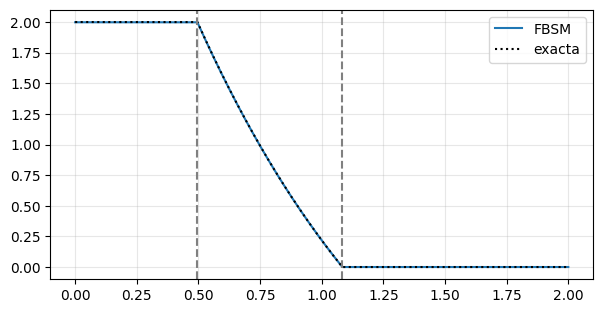

iteraciones: 10   error máx: 0.001953125


In [3]:
r = fbsm(lambda t, x, u: x + u, lambda t, x, u, l: -2 - l,
         lambda t, x, l: np.clip((l - 3)/2, 0, 2), 5.0, lambda xT: np.zeros(1), 2.0)
t = r['t']; u_ex = np.clip(np.exp(2 - t) - 2.5, 0, 2)
plt.plot(t, r['u'][:, 0], label='FBSM'); plt.plot(t, u_ex, 'k:', label='exacta')
for s in (2 - np.log(4.5), 2 - np.log(2.5)): plt.axvline(s, ls='--', c='gray')
plt.legend(); plt.show()
print('iteraciones:', r['iters'], '  error máx:', np.abs(r['u'][:, 0] - u_ex).max())

**Ejercicio 1 de la clase.** Calcular $x^*$ en cada tramo y compararlo con `r['x']`.

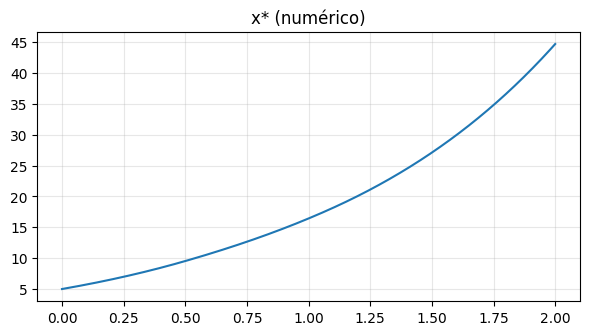

In [4]:
# Completar: x_exacta = ...
plt.plot(t, r['x'][:, 0]); plt.title('x* (numérico)'); plt.show()

## 2. Lab de Aronna (Ej. 2.2): $\max\int_0^1(Ax-u^2)$, $\dot x=-\frac12x^2+Cu$, $M_1\le u\le M_2$
Única línea que cambia respecto de la Clase 4: `np.clip`.

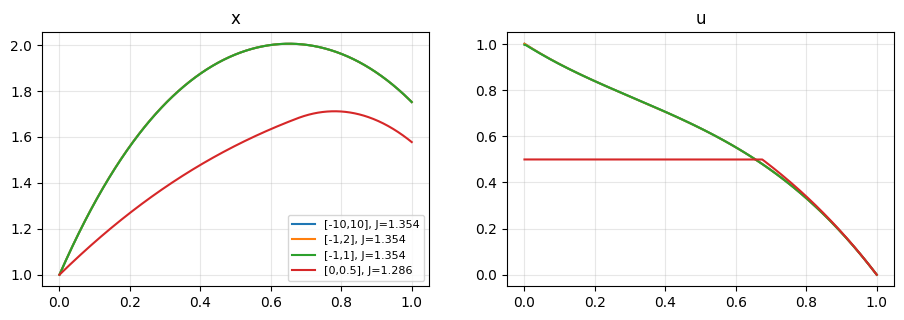

In [5]:
A, C = 1, 4
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
for (M1, M2) in [(-10, 10), (-1, 2), (-1, 1), (0, 0.5)]:
    r = fbsm(lambda t, x, u: -0.5*x**2 + C*u, lambda t, x, u, l: -A + l*x,
             lambda t, x, l: np.clip(C*l/2, M1, M2), 1.0, lambda xT: np.zeros(1), 1.0)
    J = integral(A*r['x'][:, 0] - r['u'][:, 0]**2, r['t'])
    ax[0].plot(r['t'], r['x'][:, 0], label=f'[{M1},{M2}], J={J:.3f}'); ax[1].plot(r['t'], r['u'][:, 0])
ax[0].legend(fontsize=8); ax[0].set_title('x'); ax[1].set_title('u'); plt.show()

## 3. Lab de Aronna (Ej. 9): $\max\int_0^1(x-u)$, $\dot x=2u(1-u)$, $0\le u\le1$
A mano: $\lambda=1-t$ y $u^*=\max\{0,\frac12-\frac{1}{4(1-t)}\}$.

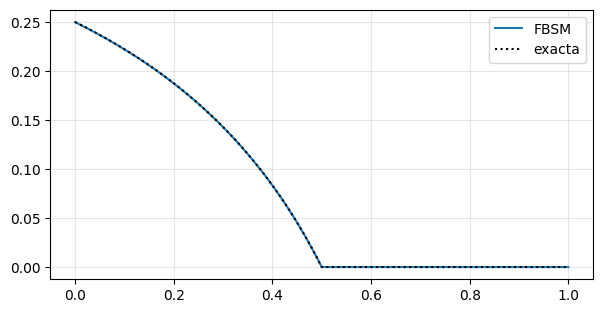

In [6]:
def ucalc9(t, x, l):
    if l <= 0.5:              # entonces 1/2 - 1/(4 l) <= 0
        return 0.0
    return np.clip(0.5 - 1/(4*l), 0, 1)
r = fbsm(lambda t, x, u: 2*u*(1 - u), lambda t, x, u, l: -1.0 + 0*l, ucalc9,
         0.0, lambda xT: np.zeros(1), 1.0)
t = r['t']; u_ex = np.maximum(0, 0.5 - 1/(4*np.maximum(1 - t, 1e-12)))
plt.plot(t, r['u'][:, 0], label='FBSM'); plt.plot(t, u_ex, 'k:', label='exacta'); plt.legend(); plt.show()

## 4. Moho y fungicida (L&W, Lab 2), con cotas
$\min\int_0^T(Ax^2+u^2)$, $\dot x=r(M-x)-ux$, $0\le u\le u_{\max}$. *Parámetros de ejemplo* (cambiarlos):
$r=0.3$, $M=10$, $A=1$, $x_0=1$, $T=5$.

Como máximo: $H=-Ax^2-u^2+\lambda(r(M-x)-ux)$, $\dot\lambda=2Ax+\lambda(r+u)$, $\lambda(T)=0$, $u=\mathrm{clip}(-\lambda x/2)$.

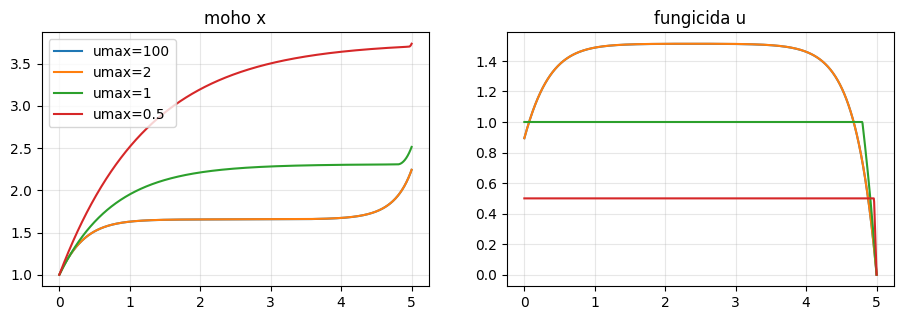

In [7]:
rr, M, A, x0, T = 0.3, 10, 1, 1.0, 5.0
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
for umax in [100, 2, 1, 0.5]:
    r = fbsm(lambda t, x, u: rr*(M - x) - u*x, lambda t, x, u, l: 2*A*x + l*(rr + u),
             lambda t, x, l: np.clip(-l*x/2, 0, umax), x0, lambda xT: np.zeros(1), T)
    ax[0].plot(r['t'], r['x'][:, 0], label=f'umax={umax}'); ax[1].plot(r['t'], r['u'][:, 0])
ax[0].legend(); ax[0].set_title('moho x'); ax[1].set_title('fungicida u'); plt.show()

## 5. Método directo con cotas: Ejemplo 8.2 otra vez
L-BFGS-B maneja cotas de caja directamente.

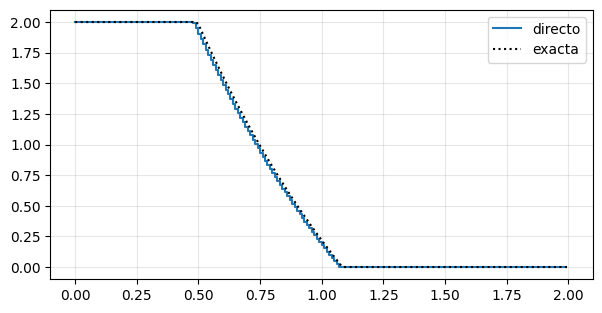

J ≈ 68.24362271465615


In [8]:
t, x, u, J = directo(lambda t, x, u: x + u, lambda t, x, u: 1.0, lambda t, x, u: 1.0,
                     lambda t, x, u: 2*x - 3*u - u**2, lambda t, x, u: 2.0, lambda t, x, u: -3 - 2*u,
                     5.0, 2.0, 200, (0, 2))
plt.step(t[:-1], u, where='post', label='directo'); plt.plot(t, np.clip(np.exp(2 - t) - 2.5, 0, 2), 'k:', label='exacta')
plt.legend(); plt.show(); print('J ≈', J)

## Para explorar
1. Tumor con dosis máxima ($\dot x = ax-u$, $0\le u\le K$): verificar numéricamente $u^*=\min\{K,\frac12 e^{a(T-t)}\}$.
2. Ejemplo con $U=\{0,1\}$ de la clase: ¿qué devuelve el FBSM si en `ucalc` maximizamos $H$ sobre $\{0,1\}$?